# Equilibrium–kinetic consistency and inference

> How can a magnetic equilibrium and kinetic profiles be combined, inferred and made physically
> consistent, and what does each way of doing it actually establish?

## 1. Physical foundations and consistency concepts

An equilibrium carries a pressure $p_\mathrm{eq}(\psi)$. Kinetic profiles imply another,

$$p_\mathrm{kin}(\psi) = p_e(\psi) + \sum_s p_{i,s}(\psi), \qquad p_e = e\,n_eT_e,\quad p_{i,s} = e\,n_{i,s}T_{i,s}.$$

The two are tied together in three different ways in VAFT. They are **not** three versions of one
"self-consistency"; each trusts a different piece of information and proves a different thing.

| Approach | Authoritative information | Main operation | Establishes | Does not establish |
|---|---|---|---|---|
| Equilibrium-constrained inference (§3) | A magnetics-only EFIT pressure | Infer the missing kinetic quantity ($T_i$) through a declared pressure-partition closure | A kinetic state compatible with that pressure **under the stated composition** | Independent agreement of $p_\mathrm{kin}$ with $p_\mathrm{eq}$; a joint reconstruction |
| Kinetic-constrained reconstruction (§4) | Thomson electron data and a declared $T_i$, $n_i$ prior | Reconstruct EFIT with a kinetic pressure constraint and assess it | A reconstruction and its archived admissibility verdict | That the prior's composition is the plasma's; an impurity-consistent joint solution |
| Self-consistent iteration (§5) | A prescribed synthetic kinetic model and a current/source policy | Re-solve a fixed-boundary CHEASE equilibrium until $p_\mathrm{eq}=p_\mathrm{kin}$ within tolerance | A numerically converged pair for those assumptions | That the pair describes a measured plasma |

Three kinds of agreement must stay apart throughout:

- **imposed by a closure**: $p_e+p_i=p_\mathrm{eq}$ after a pressure partition is an algebraic identity, not evidence;
- **independent evidence**: a measurement that did not enter the quantity it is compared with
  (Thomson against a *magnetics-only* EFIT pressure);
- **numerically achieved**: an iteration residual below a tolerance, which says the equations were
  solved, not that the inputs were right.

Sections 2–4 run fully offline from two hash-pinned archive snapshots in
`workflow/kinetic_state/archive_data/`. Section 5 is a separate, synthetic demonstration on the
packaged 39915 g-file at **319 ms** — a different state from the 316 ms experimental snapshot. Its
CHEASE solves run only when a CHEASE executable is found **and** `VAFT_RUN_CHEASE=1` is set.

In [1]:
from pathlib import Path
import hashlib
import os
import sys
import tempfile
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

import vaft
import vaft.omas
from vaft.code.chease import CHEASEConfig, find_chease_executable
from vaft.code.chease_kinetic_iteration import build_consistent_state
from vaft.data import (
    ConvergenceCriteria, CurrentPolicy, EquilibriumKineticSpec, ProfileSpec, ScalarTarget,
    SyntheticKineticSpec, TabulatedProfile, TemperatureAssumption,
)
from vaft.data.resources import sample_geqdsk
from vaft.plot import FORMATS, Panels, Profile1D, Series, render_panels
from vaft.process.kinetic_closure import infer_ti_pressure_partition
from vaft.process.profile import compose_analytic_profile, generate_synthetic_kinetic_profiles

ROOT = Path.cwd()
if not (ROOT / "workflow" / "kinetic_state").exists():
    ROOT = ROOT.parent
assert (ROOT / "workflow" / "kinetic_state").exists(), "Run from the repository root or notebooks/"
sys.path.insert(0, str(ROOT / "workflow" / "kinetic_state"))
import archive_to_ods as archive  # noqa: E402  archived snapshot -> stored kinetic state

E = archive.E
CASES = {39915: 0.316, 40326: 0.322}  # shot -> archived time [s]
snapshots = {shot: archive.load_archive(shot) for shot in CASES}
for shot, s in snapshots.items():
    assert (s["machine"], s["shot"], s["time_s"]) == ("VEST", shot, CASES[shot])
    print(f"VEST {shot} at {1e3 * s['time_s']:.0f} ms: workflow/kinetic_state/archive_data/{archive.CASES[shot]}")
    for name, item in s["provenance"].items():
        print(f"  {name:30s} {item.get('sha256', item.get('profile_sha256', ''))}")

RUN_CHEASE = os.environ.get("VAFT_RUN_CHEASE", "0") == "1"   # explicit opt-in to the solver runs
HAVE_CHEASE = find_chease_executable() is not None
EXECUTE_CHEASE = RUN_CHEASE and HAVE_CHEASE
print(f"\nCHEASE executable found: {HAVE_CHEASE}; VAFT_RUN_CHEASE=1: {RUN_CHEASE}; solver cells run: {EXECUTE_CHEASE}")
pd.set_option("display.width", 220, "display.max_columns", 30, "display.max_colwidth", 90,
              "display.float_format", "{:.4g}".format)

VEST 39915 at 316 ms: workflow/kinetic_state/archive_data/vest_39915_316ms.json
  magnetic_efit                  8f49e898e002ad6f473632849e6aa959da642ff1a838b0dcfc4b676bc055d465
  core_profiles                  e4473f3dcd4f9269a083bd974fd83385f5ac70e09832d20de9dd2a9bd9b28e2d
  electron_efit                  5cdc39024ebaea6d64f31f63046fb69a4250339e03e169ab3d89657b6f7f31bb
  resistive_zeff_atlas           70ed64794b8eb267958737666aaf0e797d95753074129774c61e8eb3f14acf17
  impurity_atlas                 306b51bca4d4eaa7d6b7367640fb00d6222cdae27142efaa366c7566a0aa046b
  electron_kinetic_state_atlas   d023ee87da53b7cf09a48a79663d2987f423bafe696099781a1b4100f202480a
  electron_efit_manifest         cd2d172bb406c822f8cfe83dc59061edd366716bdf69aaecdecbe85d18b9524c
VEST 40326 at 322 ms: workflow/kinetic_state/archive_data/vest_40326_322ms.json
  magnetic_efit                  bc9a6b066211f7c40c54a801cfc00477eb6b1b123fb64a01166b81650b66f5c4
  core_profiles                  ea74d135c2d6e3156363738

## 2. Experimental equilibrium and kinetic evidence

Each snapshot keeps, at one physical time:

| Item | Role |
|---|---|
| Magnetics-only EFIT ($p_\mathrm{eq}$, $\psi$, $\rho_{\mathrm{tor},N}$, $V$) | reconstruction; no kinetic data entered it |
| Thomson channels $n_e$, $T_e$ with reported 1σ | measurements, already **mapped** to a flux label through an equilibrium |
| Fitted $n_e(\rho)$, $T_e(\rho)$ (`core_profiles`) | reconstruction; the Thomson channels are its **fit input** |
| Electron-kinetic EFIT | reconstruction with a Thomson pressure constraint and a $T_i=T_e$, $n_i=n_e$ prior (§4) |
| Transient OpenADAS C/O charge-state fractions (plasma age from the H-α onset) | model output under an assumed composition |
| $n_C=n_O$, $\langle Z_\mathrm{eff}\rangle_{n_e\,dV}=2$ | assumptions |
| Source-product SHA-256 values | provenance |

Selection is by physical time, not array index: the magnetic EFIT and the fit share one 129-point
grid at the archived time. The Thomson points are five sparse channels, not 129 measurements.

Comparing the fit with the Thomson channels is a **fit residual**: the channels are the fit's own
input, so a residual below 1σ is local agreement, not held-out validation, and says nothing beyond
the last measured radius. The snapshots do not record the fit method or its weights. The larger
40326 residuals (up to about 4σ in $n_e$, the same under either equilibrium's mapping) are
reported here, not interpreted; the later sections use the archived fit as it is.

In [2]:
def magnetic_thomson(s):
    """The Thomson channels as mapped through the magnetics-only EFIT."""
    mapped = s["mapped_thomson"]
    return mapped["magnetics"] if "magnetics" in mapped else mapped  # 39915 archives that one mapping


rows, residuals = [], {}
for shot, s in snapshots.items():
    eq, cp, ts = s["magnetic_equilibrium"], s["core_profiles"], magnetic_thomson(s)
    rho = np.asarray(cp["rho_tor_norm"], float)
    assert eq["time_s"] == cp["time_s"] == s["time_s"]
    np.testing.assert_allclose(rho, eq["rho_tor_norm"], rtol=0, atol=1e-10)
    np.testing.assert_allclose(cp["psi_Wb"], eq["psi_Wb"], rtol=0, atol=1e-10)
    assert np.all(np.diff(rho) > 0) and len(rho) == 129
    rho_ts = np.asarray(ts["rho_tor_norm"], float)
    assert rho_ts.size == 5
    if "density_rho_tor_norm" in ts:
        np.testing.assert_allclose(rho_ts, ts["density_rho_tor_norm"], rtol=0, atol=1e-10)
    ne_fit = np.interp(rho_ts, rho, np.asarray(cp["electron_density_m3"], float))
    te_fit = np.interp(rho_ts, rho, np.asarray(cp["electron_temperature_eV"], float))
    z_ne = (np.asarray(ts["electron_density_m3"], float) - ne_fit) / np.asarray(ts["electron_density_error_m3"], float)
    z_te = (np.asarray(ts["electron_temperature_eV"], float) - te_fit) / np.asarray(ts["electron_temperature_error_eV"], float)
    residuals[shot] = (rho_ts, z_ne, z_te)
    for r, a, b in zip(rho_ts, z_ne, z_te):
        rows.append({"shot": shot, "time [ms]": round(1e3 * s["time_s"]), "rho_tor_N (magnetic map)": r,
                     "n_e (TS - fit)/sigma": a, "T_e (TS - fit)/sigma": b})
    print(f"{shot}: {len(rho)} common EFIT/core_profiles points; TS rho = {rho_ts.min():.3f}-{rho_ts.max():.3f}; "
          f"sum(residual^2) n_e = {np.sum(z_ne**2):.3f}, T_e = {np.sum(z_te**2):.3f}")
pd.DataFrame(rows).set_index(["shot", "time [ms]"])

39915: 129 common EFIT/core_profiles points; TS rho = 0.036-0.530; sum(residual^2) n_e = 2.386, T_e = 0.440
40326: 129 common EFIT/core_profiles points; TS rho = 0.046-0.476; sum(residual^2) n_e = 19.328, T_e = 7.570


rho_tor_N (magnetic map)  n_e (TS - fit)/sigma  T_e (TS - fit)/sigma
shot  time [ms]                                                                      
39915 316                          0.1692               -0.8665              -0.01097
      316                         0.03581               -0.3467               0.04624
      316                          0.1698                0.8404                0.2149
      316                          0.3624                0.7587                0.4134
      316                          0.5297               -0.4832               -0.4695
40326 322                          0.3003                -3.756               -0.1978
      322                          0.1351               -0.2754               -0.3512
      322                         0.04616                0.7221                0.9769
      322                          0.2834                 2.036                -1.689
      322                          0.4757                0.6909                 1.898

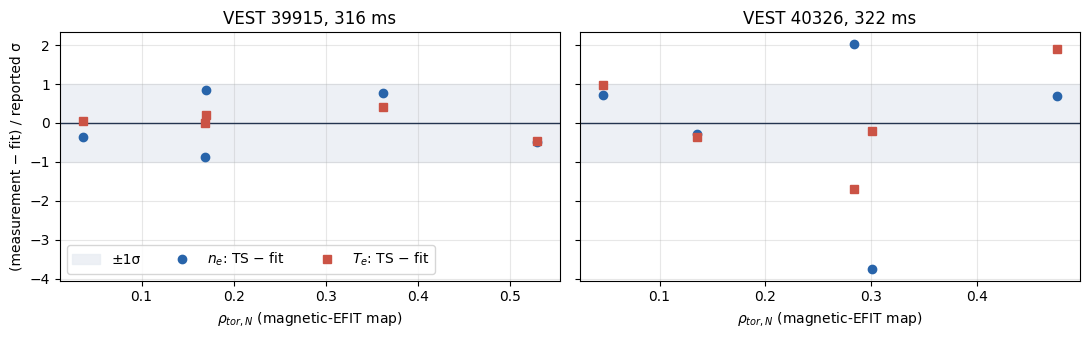

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(FORMATS["slide"].width_in, 0.6 * FORMATS["slide"].max_height_in),
                         sharey=True)
for ax, (shot, (rho_ts, z_ne, z_te)) in zip(axes, residuals.items()):
    ax.axhspan(-1, 1, color="#e9edf3", alpha=.8, label="±1σ")
    ax.axhline(0, color="#23344f", lw=1)
    ax.plot(rho_ts, z_ne, "o", color="#2864aa", label=r"$n_e$: TS − fit")
    ax.plot(rho_ts, z_te, "s", color="#cb5345", label=r"$T_e$: TS − fit")
    ax.set(xlabel=r"$\rho_{tor,N}$ (magnetic-EFIT map)", title=f"VEST {shot}, {1e3 * CASES[shot]:.0f} ms")
    ax.grid(alpha=.3)
axes[0].set_ylabel("(measurement − fit) / reported σ")
axes[0].legend(ncol=3, loc="lower left")
fig.tight_layout()
plt.show()

### Charge states: optional atomic-data replay

The archived C/O charge-state fractions are the exact resolver output used for each case, so all
later cells run from them without a download. When the hash-pinned ADF11 tables are in VAFT's
cache, this cell replays the transient resolver from the archived $T_e$, $n_e$, plasma age and
volume weights and compares fractions and $Z_\mathrm{eff}$ with the archive.

In [4]:
from vaft.data.open_adas import get_adf11_path
from vaft.process.impurity import resolve_radial_composition

for shot, s in snapshots.items():
    cp, eq = s["core_profiles"], s["magnetic_equilibrium"]
    model, charge = s["impurity_model"], s["openadas_charge_states"]
    rho = np.asarray(cp["rho_tor_norm"], float)
    edges = np.concatenate(([0.0], 0.5 * (rho[:-1] + rho[1:]), [rho[-1]]))
    dV = np.clip(np.diff(np.interp(edges, rho, np.asarray(eq["volume_m3"], float))), 0.0, None)
    try:
        for filename, expected in charge["adf11_sha256"].items():
            actual = hashlib.sha256(get_adf11_path(filename).read_bytes()).hexdigest()
            assert actual == expected, f"ADF11 SHA-256 mismatch: {filename}"
        with warnings.catch_warnings():
            warnings.filterwarnings("ignore", message="All-NaN slice encountered", category=RuntimeWarning)
            replay = resolve_radial_composition(
                np.asarray(cp["electron_temperature_eV"], float), np.asarray(cp["electron_density_m3"], float),
                rho, model["elemental_weights"], normalization="ne_weighted_mean",
                target_zeff=float(model["target_zeff"]), ionization="transient",
                plasma_age_s=model["plasma_age_s"], volume_weights=dV, time=s["time_s"])
        for element in ("C", "O"):
            np.testing.assert_allclose(replay.charge_state_fractions[replay.elements.index(element)],
                                       np.asarray(charge[element], float), rtol=1e-10, atol=1e-12, equal_nan=True)
        np.testing.assert_allclose(replay.zeff, archive.kinetic_state_case(shot, "magnetics").zeff,
                                   rtol=1e-10, atol=1e-12, equal_nan=True)
        print(f"{shot}: OpenADAS replay matches the archived C/O charge states and Z_eff profile.")
    except (OSError, ConnectionError) as exc:
        print(f"{shot}: ADF11 replay unavailable; the archived charge fractions remain usable:", exc)

39915: OpenADAS replay matches the archived C/O charge states and Z_eff profile.
40326: OpenADAS replay matches the archived C/O charge states and Z_eff profile.


## 3. Kinetic-state inference from the magnetic equilibrium

One workflow serves both cases: `archive.kinetic_state_case(shot, "magnetics")` applies the
composition and pressure partition to the snapshot and writes the result through VAFT's own writers
into an IMAS `core_profiles` slice, with each quantity's provenance in its `*_fit.parameters`
record.

- **Composition.** With $n_C=n_O=c\,n_e/2$ and charge-state fractions $f_{s,q}$, quasineutrality
  gives $n_H=n_e-\sum_s n_s\langle Z\rangle_s$ and $Z_\mathrm{eff}=(n_H+\sum_s n_s\langle Z^2\rangle_s)/n_e$.
  The scale $c$ is set so that the $n_e\,dV$-weighted **mean** of $Z_\mathrm{eff}$ is 2; the local
  $Z_\mathrm{eff}(\rho)$ is not flat. Only charged C/O states enter the ion density.
- **Partition.** `vaft.process.kinetic_closure.infer_ti_pressure_partition` receives the local
  charged-ion fraction $n_i/n_e$ and returns the common ion temperature from
  $p_i=p_\mathrm{eq}-p_e$. It takes a scalar fraction, so it is applied point by point. Points with
  undefined charge states or nonpositive residual pressure stay empty; no $T_i$ uncertainty is
  invented, because the archived inputs carry none.
- **Status.** $p_\mathrm{kin}=p_\mathrm{eq}$ at every valid point is imposed by this closure. It is
  not a test of the equilibrium.

The cell checks the converter against independent numbers: the archived atlas $Z_\mathrm{eff}$ on
axis and at $\rho=0.9$, the weighted mean, and the closure identity. The transient (not coronal)
charge-state model is used because the coronal-equilibrium validity check fails almost everywhere:
for 39915 at 127 of 128 finite points.

In [5]:
ATLAS_ZEFF = {  # (axis, rho = 0.9) from each case's impurity atlas row
    39915: (1.3276842011353556, 1.7190221792755789),
    40326: (snapshots[40326]["impurity_model"]["atlas_zeff_axis"], snapshots[40326]["impurity_model"]["atlas_zeff_rho09"]),
}
states = {shot: archive.kinetic_state_case(shot, "magnetics") for shot in CASES}
summary = {}
for shot, st in states.items():
    vc, vt = st.valid_charge, st.valid_ti
    n_ion = st.n_h + st.n_imp
    np.testing.assert_allclose(st.notes["zeff_mean"], 2.0, rtol=1e-12)
    np.testing.assert_allclose(st.zeff[0], ATLAS_ZEFF[shot][0], rtol=1e-12)
    np.testing.assert_allclose(np.interp(0.9, st.rho[vc], st.zeff[vc]), ATLAS_ZEFF[shot][1], rtol=1e-12)
    assert np.all(st.n_h[vc] >= 0)
    np.testing.assert_allclose(st.p_kin[vt], st.p_eq[vt], rtol=1e-12, atol=1e-12)
    summary[shot] = {
        "time [ms]": round(1e3 * st.time),
        "finite charge-state points": f"{vc.sum()}/{vc.size}",
        "physical T_i points": f"{vt.sum()}/{vt.size}",
        "<Z_eff>_(n_e dV) (assumed)": st.notes["zeff_mean"],
        "Z_eff axis": st.zeff[0],
        "Z_eff(0.9)": np.interp(0.9, st.rho[vc], st.zeff[vc]),
        "Z_eff min/max": f"{np.nanmin(st.zeff):.3f}/{np.nanmax(st.zeff):.3f}",
        "n_C/n_e = n_O/n_e (assumed ratio, model scale)": 0.5 * float(
            snapshots[shot]["impurity_model"].get("scale", snapshots[shot]["openadas_charge_states"].get("scale"))),
        "n_i/n_e range": f"{np.nanmin((n_ion / st.n_e)[vc]):.3f}-{np.nanmax((n_ion / st.n_e)[vc]):.3f}",
        "T_i range [eV]": f"{np.nanmin(st.t_i):.2f}-{np.nanmax(st.t_i):.2f}",
        "max|p_kin - p_eq| [Pa] (identity)": np.nanmax(np.abs(st.p_kin - st.p_eq)),
        "last TS rho": st.ts_rho.max(),
    }
pd.DataFrame(summary)

,39915,40326
time [ms],316,322
finite charge-state points,128/129,128/129
physical T_i points,128/129,117/129
<Z_eff>_(n_e dV) (assumed),2,2
Z_eff axis,1.328,2.022
Z_eff(0.9),1.719,1.511
Z_eff min/max,1.006/2.055,1.000/2.047
"n_C/n_e = n_O/n_e (assumed ratio, model scale)",0.02288,0.02495
n_i/n_e range,0.805-0.997,0.800-1.000
T_i range [eV],1.02-293.61,0.37-62.80


**40326: pressure residual at the measured channels.** Only the 40326 snapshot archives the
magnetic $p_\mathrm{eq}$ at each Thomson channel, so only there can the residual $p_\mathrm{eq}-p_e^\mathrm{TS}$
be evaluated at the channels themselves. All five are positive under the C/O composition. This is a
physical-positivity check on the magnetic pressure; it is not an uncertainty for $T_i$.

In [6]:
st, ts = states[40326], snapshots[40326]["mapped_thomson"]["magnetics"]
rt = np.asarray(ts["rho_tor_norm"], float)
ne_ts, te_ts = np.asarray(ts["electron_density_m3"], float), np.asarray(ts["electron_temperature_eV"], float)
ni_fraction = np.interp(rt, st.rho[st.valid_charge], ((st.n_h + st.n_imp) / st.n_e)[st.valid_charge])
p_eq_ts = np.asarray(ts["p_eq_Pa"], float)
ti_channels = (p_eq_ts - E * ne_ts * te_ts) / (E * ne_ts * ni_fraction)
assert np.all(ti_channels > 0)
pd.DataFrame({"rho_tor_N (magnetic map)": rt, "p_eq - p_e^TS [Pa]": p_eq_ts - E * ne_ts * te_ts,
              "T_i (C/O) [eV]": ti_channels}).rename_axis("channel")

,rho_tor_N (magnetic map),p_eq - p_e^TS [Pa],T_i (C/O) [eV]
channel,,,
0,0.3003,216.5,90.67
1,0.1351,149,43.13
2,0.04616,127.2,33.53
3,0.2834,155.1,40.98
4,0.4757,144,47.9


### The canonical kinetic-state figure

`vaft.omas.plot_kinetic_overview_state` draws pressure, density, temperature and $Z_\mathrm{eff}$
from stored IMAS paths only; every legend entry names the role recorded by the writer. It maps the
Thomson channels from $(R,Z)$ through the stored equilibrium. The snapshots keep each channel's
mapped label, not the 2-D EFIT flux map, so the converter supplies a **synthetic** midplane map on
which each channel lands exactly at its archived $\psi_N$; the mapped radii are checked here.

Read the roles in context. `independent validation` on $p_e^\mathrm{TS}$ means Thomson pressure
against the **magnetics-only** EFIT pressure, which used no Thomson data. The density and
temperature markers are `fit input`: they are the data the drawn fits came from. The shaded band is
the measured radial span; beyond it the fitted profiles and the inferred $T_i$ are extrapolation.
The dashed $\langle Z_\mathrm{eff}\rangle=2$ line is the assumed weighted-mean target, not a local
measurement.

In [7]:
role_rows = {}
for shot, st in states.items():
    view = vaft.omas.extract_kinetic_overview_state(st.ods)
    mapped = [t for t in view.models[0].series if "TS" in t.label][0]
    np.testing.assert_allclose(np.sort(mapped.x), np.sort(st.ts_rho), rtol=0, atol=2e-4)
    role_rows[shot] = {(p.metadata["panel"], t["quantity"]): t["role"]
                       for p in view.models for t in p.metadata["traces"]}
pd.DataFrame(role_rows).rename_axis(["panel", "quantity"])

39915                   40326
panel       quantity                                                       
pressure    p_eq                             stored                  stored
            p_e                              stored                  stored
            p_i                            inferred                inferred
            p_imp                       unavailable             unavailable
            p_kin                  closure identity        closure identity
            p_e_thomson      independent validation  independent validation
density     n_e                                 fit                     fit
            n_main_ion                      derived                 derived
            n_impurity_ion                  derived                 derived
            n_e_thomson                   fit input               fit input
temperature T_e                                 fit                     fit
            T_i                            inferred                inferred
            T_e_thomson                   fit input               fit input
zeff        Z_eff                           derived                 derived
            Z_eff_reference                 assumed                 assumed

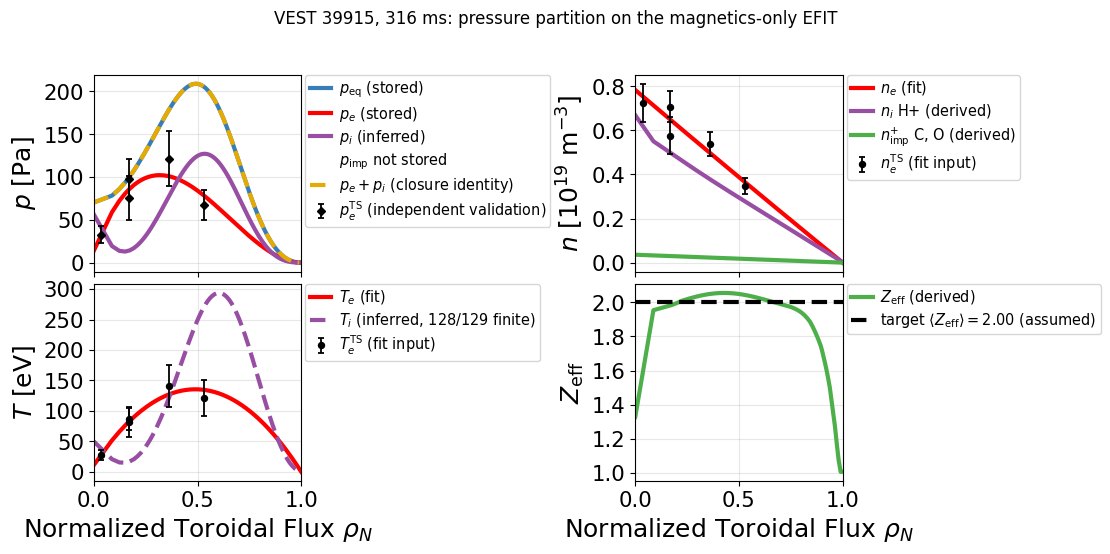

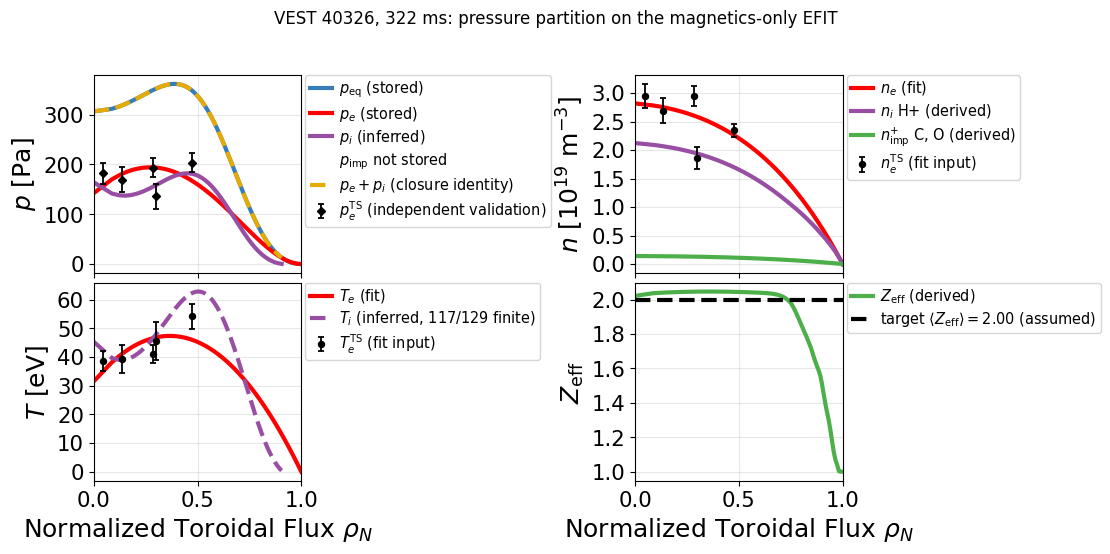

In [8]:
for shot, st in states.items():
    fig, axes = vaft.omas.plot_kinetic_overview_state(st.ods, format="slide")
    fig.suptitle(f"VEST {shot}, {1e3 * st.time:.0f} ms: pressure partition on the magnetics-only EFIT")
    plt.show()

The same four panels as one column (`layout="stack"`, `poster` format). A layout is a rendering
option of the same stored state; nothing is recomputed.

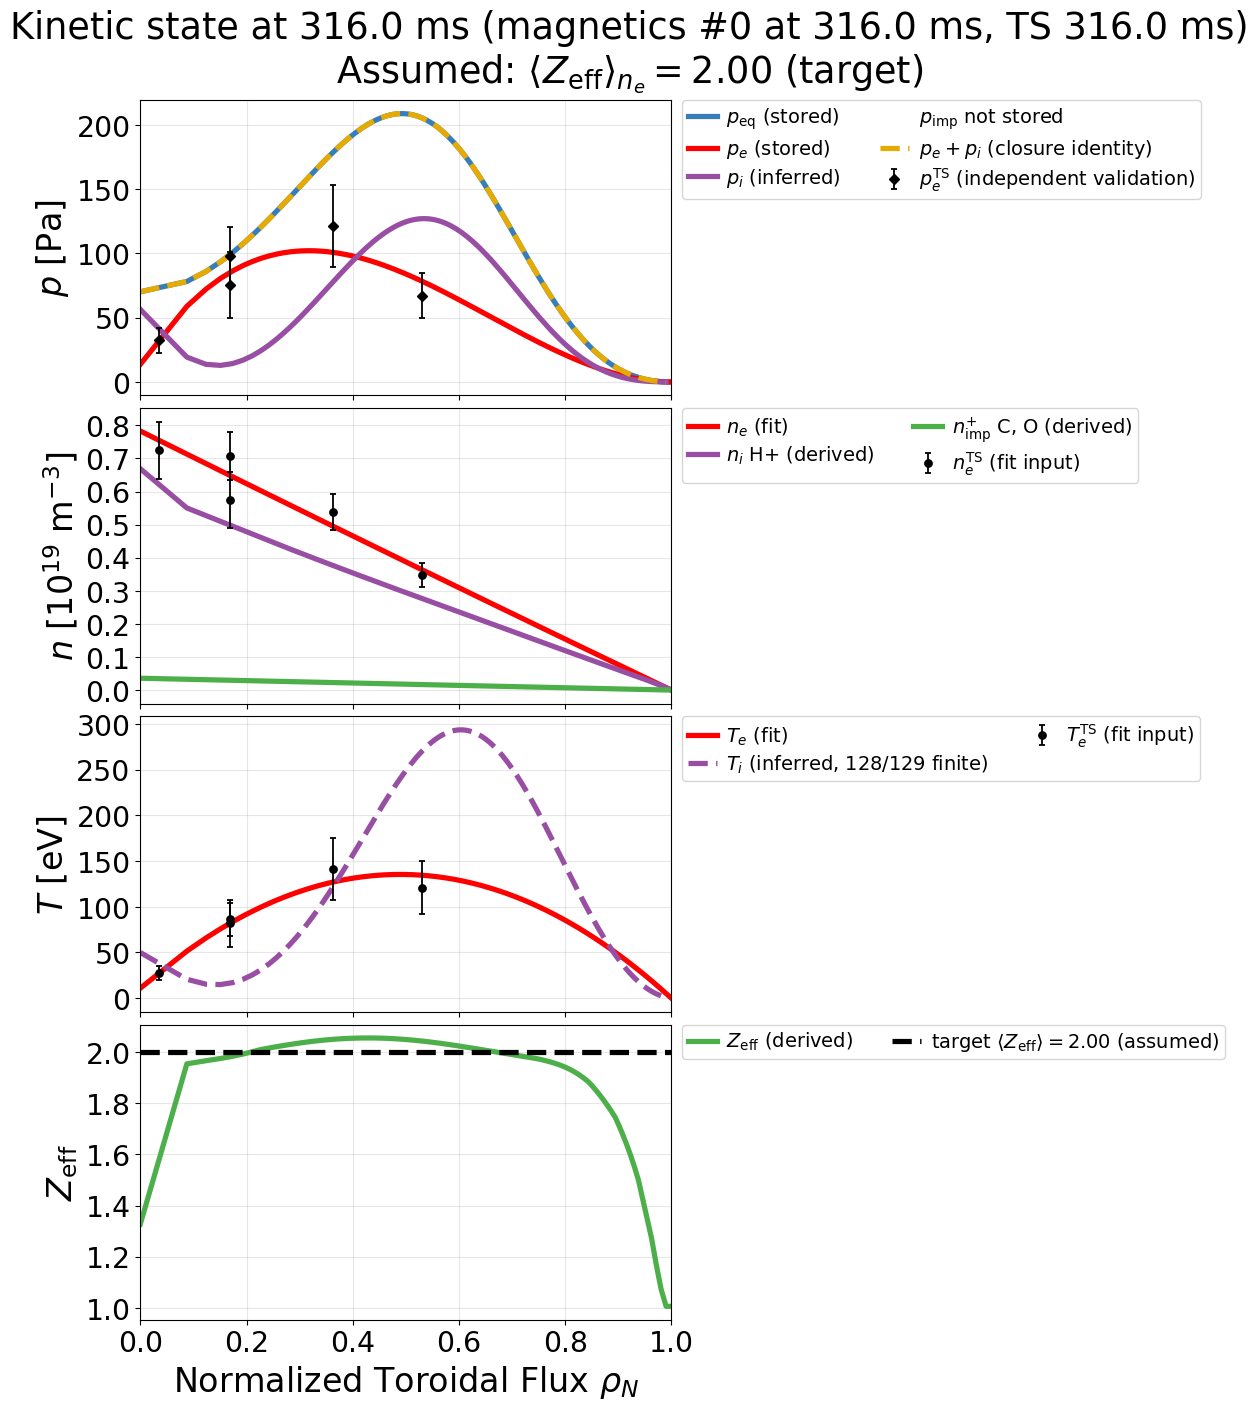

In [9]:
fig, axes = vaft.omas.plot_kinetic_overview_state(states[39915].ods, layout="stack", format="poster")
plt.show()

### Archivable state table

`archive.write_state_table` writes the magnetic-lineage state as CSV: pressures, electron and ion
densities (every C and O charge state, neutrals included), temperatures, $Z_\mathrm{eff}$ and the
validity masks, with NaN at invalid points. The 39915 file is byte-identical to the one the
original archive notebook produced; its hash is checked. Files go to `$VAFT_KINETIC_STATE_OUTPUT`
when it is set (for example `output/kinetic_state`), otherwise to a temporary directory, so an
execution never writes into the repository by default.

In [10]:
CSV_SHA256 = {39915: "44763333ab9883c597964bc2f4a47b9d93082ba5fa4babc19808d42bcbe8f0ac"}
TABLE_DIR = Path(os.environ.get("VAFT_KINETIC_STATE_OUTPUT") or tempfile.mkdtemp(prefix="vaft-kinetic-state-"))
for shot in CASES:
    name = f"vest_{shot}_{round(1e3 * CASES[shot])}ms_transient_c_o_profiles.csv"
    path = archive.write_state_table(shot, TABLE_DIR / name)
    digest = hashlib.sha256(path.read_bytes()).hexdigest()
    if shot in CSV_SHA256:
        assert digest == CSV_SHA256[shot], f"{name} changed"
    print(name, "rows", len(states[shot].rho), "sha256", digest)

vest_39915_316ms_transient_c_o_profiles.csv rows 129 sha256 44763333ab9883c597964bc2f4a47b9d93082ba5fa4babc19808d42bcbe8f0ac
vest_40326_322ms_transient_c_o_profiles.csv rows 129 sha256 892eb1fe528c7ca89e494f186e907e5b3f9ab287e81a45c6dac0ec9e4020ded1


## 4. Kinetic-constrained EFIT and assumption-aware comparison

Each snapshot also holds an `electron_efit` reconstruction at the same time. Its `raw6` pressure
constraint used $p_\mathrm{input}=e\,n_e(T_e+T_i)=2p_e$ at the five Thomson channels plus a
zero-pressure edge anchor, under the VEST fallback $T_i/T_e=1\pm0.5$ and $n_i=n_e$ (**no impurity
dilution**). Thomson is therefore a **reconstruction input** here, and the fit's alignment with
Thomson is not independent validation.

Three verdicts are archived separately and must not be merged: the solver outcome (status,
convergence), the EFIT validity, and the kinetic admissibility gate. $\chi^2$ is the solver's own
weighted sum; the snapshots do not record its weights or degrees of freedom, so it is not a ranking
across shots.

**Circularity.** The electron-kinetic pressure already contains the $T_i/T_e$ prior. Partitioning
it again would return that prior, so `infer_ti_pressure_partition` refuses it, and no $p_i$ or
$p_\mathrm{kin}$ is inferred on this lineage.

In [11]:
policies = {shot: archive.kinetic_efit_pressure_policies(shot) for shot in CASES}
rows = {}
for shot, pol in policies.items():
    a = pol.assessment
    assert a.manifest_status == "success" and a.manifest_converged and a.efit_status == "valid"
    assert a.pressure_constraint_encoding == "raw6" and a.ti_lineage == "ti_eq_te_assumed"
    assert a.ti_te_ratio_assumed == 1.0 and a.ts_status == "matched" and a.ts_points == 5
    assert "circular" in pol.refusal
    assert np.all(pol.p_counterfactual[pol.valid_charge] <= pol.p_prior[pol.valid_charge] + 1e-10)
    rows[shot] = {
        "solver status / converged": f"{a.manifest_status} / {a.manifest_converged}",
        "EFIT status": a.efit_status,
        "kinetic admissible": a.kinetic_admissible,
        "admissibility reasons": a.kinetic_admissible_reasons or "-",
        "chi2 (solver's own weights)": a.chi2,
        "r_w (own span)": a.r_w,
        "r_w (magnetic pair's psi span)": a.r_w_on_pair_span,
        "c_p": a.c_p,
        "p_eq,kin min [Pa]": pol.p_eq_kinetic.min(),
        "negative-pressure cells": f"{np.count_nonzero(pol.p_eq_kinetic < 0)}/{pol.p_eq_kinetic.size}",
        "max native rho-grid shift": np.max(np.abs(pol.rho_kinetic - pol.rho_magnetic)),
        "max native psi-grid shift [Wb]": np.max(np.abs(
            np.asarray(snapshots[shot]["electron_kinetic_equilibrium"]["psi_Wb"], float)
            - np.asarray(snapshots[shot]["magnetic_equilibrium"]["psi_Wb"], float))),
        "TS mapping (source)": pol.mapping_source,
        "TS mapped through": pol.mapping_lineage,
        "TS native to this EFIT": pol.mapping_native_to_equilibrium,
        "archived assessment keys": ", ".join(a.source_keys),
    }
k39, k40 = policies[39915], policies[40326]
assert k39.assessment.kinetic_admissible == "fail" and np.count_nonzero(k39.p_eq_kinetic < 0) == 4
np.testing.assert_allclose(k39.p_eq_kinetic.min(), -0.845745309, atol=1e-10)
assert k40.assessment.kinetic_admissible == "pass" and k40.p_eq_kinetic.min() >= 0
assert not k39.mapping_native_to_equilibrium and k40.mapping_native_to_equilibrium
# 40326: the two mappings carry the same physical channels; only their flux labels differ
mapped40 = snapshots[40326]["mapped_thomson"]
for key in ("electron_density_m3", "electron_temperature_eV"):
    np.testing.assert_array_equal(mapped40["magnetics"][key], mapped40["electron_kinetic"][key])
print("40326 Thomson labels, magnetic map:", np.round(mapped40["magnetics"]["rho_tor_norm"], 3))
print("40326 Thomson labels, kinetic map: ", np.round(mapped40["electron_kinetic"]["rho_tor_norm"], 3))
print("T_i inference guard on the electron-kinetic lineage:", k39.refusal)
pd.DataFrame(rows)

40326 Thomson labels, magnetic map: [0.3   0.135 0.046 0.283 0.476]
40326 Thomson labels, kinetic map:  [0.291 0.127 0.058 0.288 0.478]
T_i inference guard on the electron-kinetic lineage: circular: the 'electron_kinetic' equilibrium pressure was reconstructed with an assumed Ti/Te, so partitioning it returns that assumption


,39915,40326
solver status / converged,success / True,success / True
EFIT status,valid,valid
kinetic admissible,fail,pass
admissibility reasons,pressure_min -0.845745309,-
chi2 (solver's own weights),87.72,361.7
r_w (own span),1.866,1.906
r_w (magnetic pair's psi span),1.824,1.903
c_p,-0.003587,0.00944
"p_eq,kin min [Pa]",-0.8457,1.082
negative-pressure cells,4/129,0/129


**39915 fails** admissibility: the reconstruction ran, converged and is a valid EFIT, but four edge
cells have negative pressure. **40326 passes**, with nonnegative pressure everywhere.
Passing the gate does not make 40326 an impurity-consistent reconstruction: its constraint still
used $n_i=n_e$.

The pressure panels below put each shot's policies side by side:

- $p_\mathrm{eq}^\mathrm{kin}$ and $p_\mathrm{eq}^\mathrm{mag}$, each on **its own** equilibrium's
  $\rho_{\mathrm{tor},N}$. Equal labels on two equilibria are not the same place, so no pointwise
  difference is read off without a remapping;
- $2p_e^\mathrm{fit}$, the continuous form of the EFIT's prior on the `core_profiles` fit — **not**
  its six actual constraint points;
- $p_e+p_i^\mathrm{C/O}$, the same $T_i=T_e$ prior with the assumed C/O dilution: a counterfactual
  that was **not** used in either fit;
- the Thomson constraint values $2p_e^\mathrm{TS}$ with the shared $T_e$ error and $\sigma(T_i/T_e)=0.5$.
  For 40326 they are at the channels' mapping through the kinetic EFIT. 39915 archives only the
  magnetic-EFIT mapping, so its markers stay at those labels and say so; they are not remapped onto
  the kinetic equilibrium.

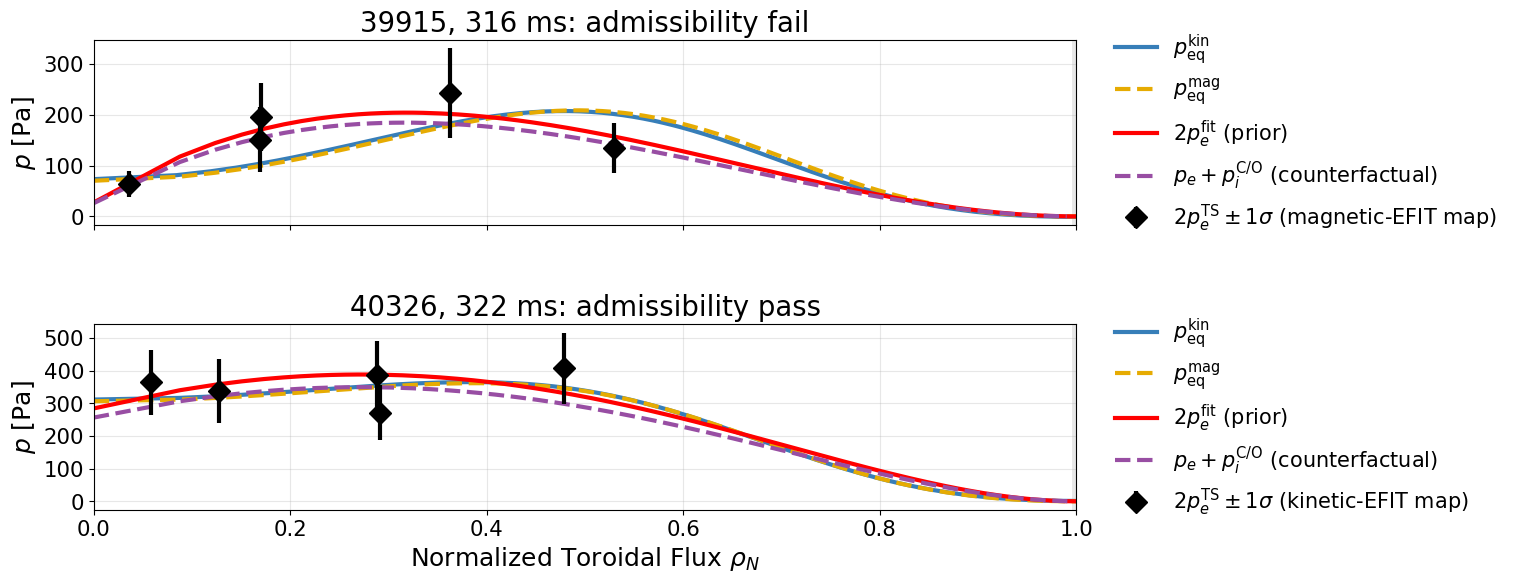

In [12]:
def series(x, y, label, *, color=None, ls="-", yerr=None, marker=None, mask=None):
    style = {"linestyle": ls}
    if color is not None:
        style["color"] = color
    if marker is not None:
        style["marker"] = marker
    return Series(x=x, y=y, label=label, yerr=yerr, style=style, valid_mask=mask)


def pressure_policy_panel(pol, coordinate_label):
    ts_map = {"electron_kinetic": "kinetic-EFIT map", "magnetics": "magnetic-EFIT map"}[pol.mapping_lineage]
    return Profile1D(series=(
        series(pol.rho_kinetic, pol.p_eq_kinetic, r"$p_{\mathrm{eq}}^{\mathrm{kin}}$", color="palette:0"),
        series(pol.rho_magnetic, pol.p_eq_magnetic, r"$p_{\mathrm{eq}}^{\mathrm{mag}}$", color="palette:7", ls="--"),
        series(pol.rho, pol.p_prior, r"$2p_e^{\mathrm{fit}}$ (prior)", color="role:reconstructed"),
        series(pol.rho, pol.p_counterfactual, r"$p_e+p_i^{\mathrm{C/O}}$ (counterfactual)", color="palette:2",
               ls="--", mask=pol.valid_charge),
        series(pol.ts_rho, pol.ts_p_input, rf"$2p_e^{{\mathrm{{TS}}}}\pm1\sigma$ ({ts_map})", color="role:measured",
               yerr=pol.ts_sigma_p_input, marker="D", ls="none"),
    ), coordinate_label=coordinate_label, y_label=r"$p$", y_unit="Pa", x_limits=(0, 1),
       title=f"{pol.shot}, {1e3 * pol.time:.0f} ms: admissibility {pol.assessment.kinetic_admissible}",
       metadata={"ts_mapping_source": pol.mapping_source, "ts_mapping_lineage": pol.mapping_lineage,
                 "ts_mapping_native_to_equilibrium": pol.mapping_native_to_equilibrium})


xlabel = vaft.omas.extract_kinetic_overview_state(states[40326].ods).models[0].coordinate_label
policy_panels = tuple(pressure_policy_panel(pol, xlabel) for pol in policies.values())
fig, axes = render_panels(Panels(models=policy_panels, nrows=2, ncols=1, share_x=True), format="slide")
for ax in np.asarray(axes).flat:  # five entries: beside the axes, clear of the profiles
    legend = ax.get_legend()
    ax.legend(loc="center left", bbox_to_anchor=(1.02, 0.5), prop=legend.prop, frameon=False)
plt.show()

### 40326 on its own kinetic EFIT

For the admissible case the canonical figure can also be drawn on the electron-kinetic lineage,
because its Thomson channels have their own mapping through that equilibrium. Here $T_i$ is the
EFIT's **prior** $T_i=T_e$ (role `assumed`), and the pressure panel carries no $p_i$ or
$p_\mathrm{kin}$: nothing is inferred from a pressure that already contains the prior, and the
Thomson pressure is a `fit input`. The fitted electron curves keep the magnetic `core_profiles`
coordinate while the Thomson markers use the kinetic-EFIT mapping; they are compared by label, not
remapped point by point. The ion densities and $Z_\mathrm{eff}$ are the assumed C/O
composition, which this EFIT did not use. 39915 is not drawn this way: its channels have no
kinetic-EFIT mapping.

{'p_eq': 'stored', 'p_e_thomson': 'fit input', 'T_i': 'assumed', 'n_impurity_ion': 'derived', 'Z_eff': 'derived'}


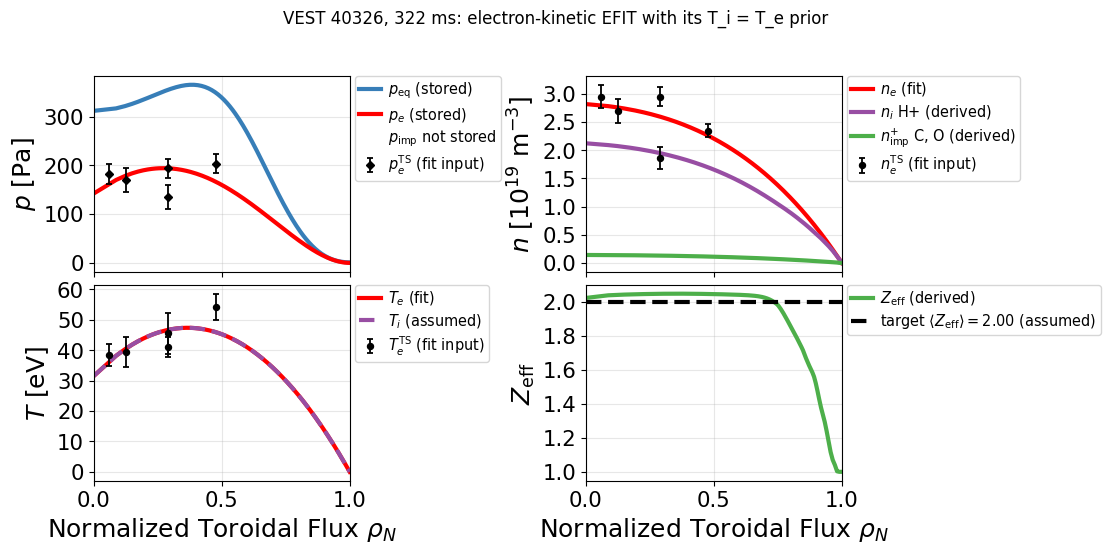

In [13]:
kinetic_40326 = archive.kinetic_state_case(40326, "electron_kinetic")
view = vaft.omas.extract_kinetic_overview_state(kinetic_40326.ods)
roles = {t["quantity"]: t["role"] for p in view.models for t in p.metadata["traces"]}
assert roles["T_i"] == "assumed" and roles["p_e_thomson"] == "fit input"
assert "p_i" not in roles and "p_kin" not in roles
assert view.models[0].metadata["equilibrium_lineage"] == "electron_kinetic"
print({q: roles[q] for q in ("p_eq", "p_e_thomson", "T_i", "n_impurity_ion", "Z_eff")})
fig, axes = vaft.omas.plot_kinetic_overview_state(kinetic_40326.ods, format="slide")
fig.suptitle("VEST 40326, 322 ms: electron-kinetic EFIT with its T_i = T_e prior")
plt.show()

**What §4 shows.** The two kinetic EFITs are time matched with Thomson. The atlas pressure ratios
($r_w$, $c_p$) are alignment diagnostics for fits that already used Thomson pressure, not
independent evidence for $T_i$. Neither archive establishes an H/C/O, $\langle Z_\mathrm{eff}\rangle=2$
kinetic EFIT: that would need a new reconstruction with an impurity-diluted pressure constraint,
followed by remapping, diagnostics and the admissibility gate.

## 5. Self-consistent equilibrium–kinetic iteration (synthetic)

Sections 3 and 4 never change the equilibrium. Here the kinetic pressure is made authoritative and
the equilibrium is re-solved for it. `vaft.code.chease_kinetic_iteration.build_consistent_state`
composes three existing pieces and adds no physics of its own:

1. `generate_synthetic_kinetic_profiles` builds $n_e,T_e,T_i,n_i$ from the equilibrium and **one
   unchanging** `SyntheticKineticSpec`. Each new equilibrium gets profiles regenerated from that
   spec; nothing is re-interpolated from an earlier iteration.
2. A **CHEASE pressure source** is built from $p_\mathrm{kin}$: `PRES` and `PPRIME` $=dp/d\psi$ from
   a monotone PCHIP interpolant and its analytic derivative, without smoothing or clipping. $FF'$
   comes from an explicit **current policy**.
3. A **fixed-boundary CHEASE solve** (`target_psin = 1`, so the initial `RBBBS` is the boundary
   every time). Each solve is validated before it is accepted.

| Mode | Authoritative pressure | What happens |
|---|---|---|
| `equilibrium_pressure` | $p_\mathrm{eq}$ | the kinetic spec decomposes $p_\mathrm{eq}$ once; no CHEASE |
| `kinetic_pressure` | $p_\mathrm{kin}$ | CHEASE re-solves for $p_\mathrm{kin}$, profiles are regenerated on the new equilibrium, repeat |

The result is an **assumption-driven** consistent state: the kinetic profiles are declared, not
measured, transport-predicted or reconstructed.

**This is not the experimental state of §2–4.** The input is the packaged VEST 39915 g-file at
**319 ms**; the inference snapshot is at 316 ms. The kinetic profiles are synthetic.

**Numerics.** The solves use a coarse demo mesh, `NS = NT = 50` with a 129 × 129 output box
(adapter default 150 and 513). The mesh sets the local force balance more than the global
quantities, so the convergence history is representative, but the equilibria are not production
quality.

In [14]:
TIME = 0.319
assert TIME != snapshots[39915]["time_s"]   # the packaged g-file, not the 316 ms inference snapshot
WORK = Path(tempfile.mkdtemp(prefix="vaft-kinetic-iteration-"))
DEMO_MESH = CHEASEConfig(nw=129, ns=50, nt=50, create_plot=False)   # coarse demo mesh, see above
g0 = sample_geqdsk()

# The declared kinetic assumptions, held fixed for the whole iteration.
kinetic = SyntheticKineticSpec(
    n_e=ProfileSpec(compose_analytic_profile("n_e", axis_value=1.0, separatrix_value=0.2, core_beta=1.5),
                    ScalarTarget("volume_average", 6e18)),          # <n_e>_V fixed: re-normalized on every new V(psi)
    T_e=ProfileSpec(compose_analytic_profile("T_e", axis_value=150.0, separatrix_value=10.0, core_beta=2.0)),
    temperature=TemperatureAssumption(ti_over_te=0.5),
    pressure_constraint="kinetic",                                   # every channel as declared
    label="39915 demo kinetic assumptions",
)
print(f"Synthetic demonstration on the packaged g-file at {1e3 * TIME:.0f} ms "
      f"(experimental snapshot: {1e3 * snapshots[39915]['time_s']:.0f} ms)")

Synthetic demonstration on the packaged g-file at 319 ms (experimental snapshot: 316 ms)


### The starting point: $p_\mathrm{kin}$ against $p_\mathrm{eq}$

The declared profiles imply a pressure below the EFIT pressure inside $\psi_N\approx0.9$, with
39 % less stored energy, and finite at the separatrix. That mismatch is what the iteration removes.

success - kinetic profiles as specified; the source equilibrium is NOT pressure-consistent (max |p_kin - p_eq|/max p_eq = 0.268)


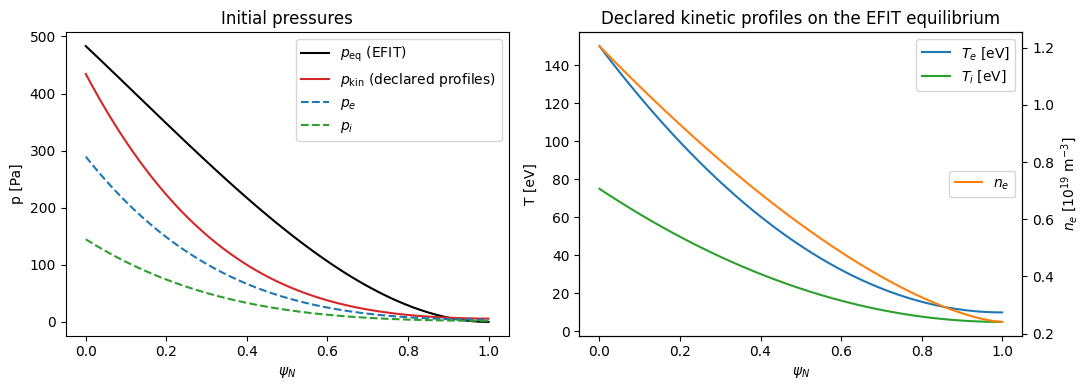

max|p_kin - p_eq| / max p_eq = 0.268;  W_kin/W_eq - 1 = -0.387


In [15]:
kin0 = generate_synthetic_kinetic_profiles(g0, kinetic, time=TIME)
print(kin0.status, "-", kin0.message)
fig, (ax, bx) = plt.subplots(1, 2, figsize=(11, 4))
ax.plot(kin0.psi_norm, kin0.p_eq, "k-", label=r"$p_\mathrm{eq}$ (EFIT)")
ax.plot(kin0.psi_norm, kin0.p_total, "C3-", label=r"$p_\mathrm{kin}$ (declared profiles)")
ax.plot(kin0.psi_norm, kin0.p_e, "C0--", label=r"$p_e$")
ax.plot(kin0.psi_norm, kin0.p_i, "C2--", label=r"$p_i$")
ax.set(xlabel=r"$\psi_N$", ylabel="p [Pa]", title="Initial pressures"); ax.legend()
bx.plot(kin0.psi_norm, kin0.T_e, "C0-", label=r"$T_e$ [eV]")
bx.plot(kin0.psi_norm, kin0.T_i, "C2-", label=r"$T_i$ [eV]")
b2 = bx.twinx(); b2.plot(kin0.psi_norm, kin0.n_e / 1e19, "C1-", label=r"$n_e$")
b2.set_ylabel(r"$n_e$ [$10^{19}$ m$^{-3}$]")
bx.set(xlabel=r"$\psi_N$", ylabel="T [eV]", title="Declared kinetic profiles on the EFIT equilibrium")
bx.legend(loc="upper right"); b2.legend(loc="center right")
fig.tight_layout(); plt.show()
print(f"max|p_kin - p_eq| / max p_eq = {kin0.pressure.max_relative_residual:.3f};  "
      f"W_kin/W_eq - 1 = {kin0.pressure.thermal_energy_relative_difference:+.3f}")

### Mode `equilibrium_pressure`: keep $p_\mathrm{eq}$ and decompose it

With the equilibrium pressure authoritative, the kinetic spec must close the pressure
(`pressure_constraint="equilibrium"`); `closure="temperature"` solves $T_e(\psi)$ so that
$p_\mathrm{kin}=p_\mathrm{eq}$ with $n_e$ and $T_i/T_e$ held. This is the synthetic counterpart of
§3's closure: consistent after one pass, by construction, with no CHEASE call.

In [16]:
decompose = EquilibriumKineticSpec(
    SyntheticKineticSpec(n_e=kinetic.n_e, temperature=kinetic.temperature,
                         pressure_constraint="equilibrium", closure="temperature"),
    closure="equilibrium_pressure")
eq_mode = build_consistent_state(g0, decompose, workdir=WORK / "equilibrium_pressure", time=TIME)
print(eq_mode.status, "-", eq_mode.message)
print("CHEASE updates:", len(eq_mode.iterations), "| files written:", list((WORK / "equilibrium_pressure").glob("*")))
pd.DataFrame(eq_mode.assumption_table(), columns=["quantity", "role"])

converged - the given equilibrium's pressure is decomposed by the #122 closure 'temperature': closure residual max|p_kin - p_eq|/max p_eq = 2.35e-16 up to psi_N = 0.9025; no CHEASE update is requested
CHEASE updates: 0 | files written: []


,quantity,role
0,"kinetic assumptions (the #122 spec: held channels, T_i route, composition)",held
1,"the given equilibrium: psi(R,Z), p_eq, q(psi), boundary",held (no CHEASE update)
2,the channel the closure solves so that p_kin = p_eq,recomputed from the kinetic state
3,"n_i, Z_eff, p_e, p_i",recomputed from the kinetic state
4,pressure closure residual,convergence metric


### Mode `kinetic_pressure`: re-solve the equilibrium for $p_\mathrm{kin}$

Pressure alone does not fix a Grad–Shafranov equilibrium; the non-pressure source is declared by a
`CurrentPolicy`:

- `preserve_ffprime_shape` keeps the **initial** equilibrium's normalized $FF'(\psi_N)$, re-sampled
  from that one array every update, with the amplitude carried over from the previous solve;
- `analytic_ffprime_shape` uses $FF'\propto-dg/d\psi_N$ of a declared analytic profile $g$ (shown
  below).

CHEASE imposes one normalization, $I_p$ (`NCSCAL = 2`, used here) or $q_{95}$ (`NCSCAL = 1`), and
rescales $p'$ and $FF'$ together to meet it, so the split of the current between them is
**re-solved**. $q$ is always an output. The held value is taken once from the initial equilibrium
and requested in every input ($I_p$ as `CURRENT`; for $q_{95}$, `QPSI` rescaled so the adapter's
`QSPEC` sample at $\psi_N=0.95$ equals the target), so a solver bias cannot accumulate.

Each update is accepted only if a solution exists, the arrays are finite, $p\ge0$, the axis lies
inside the boundary, CHEASE's solved boundary and the `EXPEQ` boundary agree within 1 % of a
half-width (symmetric Hausdorff distance), the held $I_p$ or $q_{95}$ is met to $10^{-3}$, the
$I_p$/$B_0$ orientation is unchanged and $|F_\mathrm{edge}|$ is held.

Convergence needs **all** of: the pressure residual $\max|p_\mathrm{kin}-p_\mathrm{eq}|/\max p_\mathrm{kin}$
of the *new* equilibrium; the changes of $p_\mathrm{kin}$, $p_\mathrm{eq}$, $n_e$, $T_e$, $T_i$,
$n_i$, $|q|$, the $\rho_\mathrm{tor}(\psi_N)$ map and $q_0$, $q_{95}$, $l_i$, $\beta_p$, $W_\mathrm{th}$
(each $\le10^{-3}$); and an axis change of at most $10^{-4}$ m.

In [17]:
spec = EquilibriumKineticSpec(kinetic, closure="kinetic_pressure",
                              current_policy=CurrentPolicy("preserve_ffprime_shape", "plasma_current"),
                              convergence=ConvergenceCriteria(max_iterations=10))
iteration = None
if EXECUTE_CHEASE:
    iteration = build_consistent_state(g0, spec, config=DEMO_MESH, workdir=WORK / "kinetic_pressure", time=TIME,
                                       baseline=True)
    print(iteration.status, "-", iteration.message)
    rows = []
    for s in iteration.states:
        m, c = s.metrics, s.scalars
        rows.append({"state": s.index, "status": s.status,
                     "max|p_kin-p_eq|/max p_kin": m.get("pressure_max_relative"),
                     "W_kin/W_eq-1": m.get("thermal_energy_relative"),
                     "|dp_kin|": m.get("p_kin_change"), "|dp_eq|": m.get("p_eq_change"),
                     "|dq|": m.get("q_change"), "|drho_tor|": m.get("rho_tor_change"),
                     "Ip [kA]": c["ip"] / 1e3, "q0": c["q0"], "q95": c["q95"], "li": c["li"],
                     "beta_p": c["beta_p"], "R_axis [m]": c["magnetic_axis_r"], "W_th [J]": c.get("w_th")})
    display(pd.DataFrame(rows).set_index("state"))
else:
    print("Skipping the kinetic_pressure solves:",
          "set VAFT_RUN_CHEASE=1 to run them." if HAVE_CHEASE else "no CHEASE executable was found.")

converged - every enabled criterion met after 4 update(s): max|p_kin - p_eq|/max p_kin = 9.72e-05


,status,max|p_kin-p_eq|/max p_kin,W_kin/W_eq-1,|dp_kin|,|dp_eq|,|dq|,|drho_tor|,Ip [kA],q0,q95,li,beta_p,R_axis [m],W_th [J]
state,,,,,,,,,,,,,,
0,initial,0.2982,-0.3871,NaN,NaN,NaN,NaN,77.04,1.96,8.839,0.6894,0.2708,0.4813,280.2
1,accepted,0.235,-0.1804,0.06198,0.1553,0.0557,0.03996,77.04,1.235,8.387,0.8185,0.1883,0.4876,193.3
2,accepted,0.002942,0.002162,0.01153,0.2529,0.01591,0.01089,77.04,1.376,8.448,0.7796,0.1563,0.4828,160.4
3,accepted,0.000155,-0.0001468,0.0001599,0.003183,0.0002157,0.0001528,77.04,1.374,8.447,0.7802,0.1566,0.4829,160.7
4,accepted,9.716e-05,-9.759e-05,3.134e-06,6.331e-05,4.246e-06,2.994e-06,77.04,1.374,8.447,0.7802,0.1566,0.4829,160.7


#### Iteration history

State 0 is the EFIT equilibrium; each later state is one CHEASE update measured **after** the solve.
CHEASE rescales $p'$ and $FF'$ by one factor to hold $I_p$, and the solved $FF'$ amplitude is carried
into the next input, so that factor contracts to one at a rate set roughly by the pressure-driven
share of the current. The first update both replaces the pressure and moves from EFIT's solution to
CHEASE's on the same boundary; after that the residual falls by more than an order of magnitude per
update to the interpolation floor near $10^{-4}$.

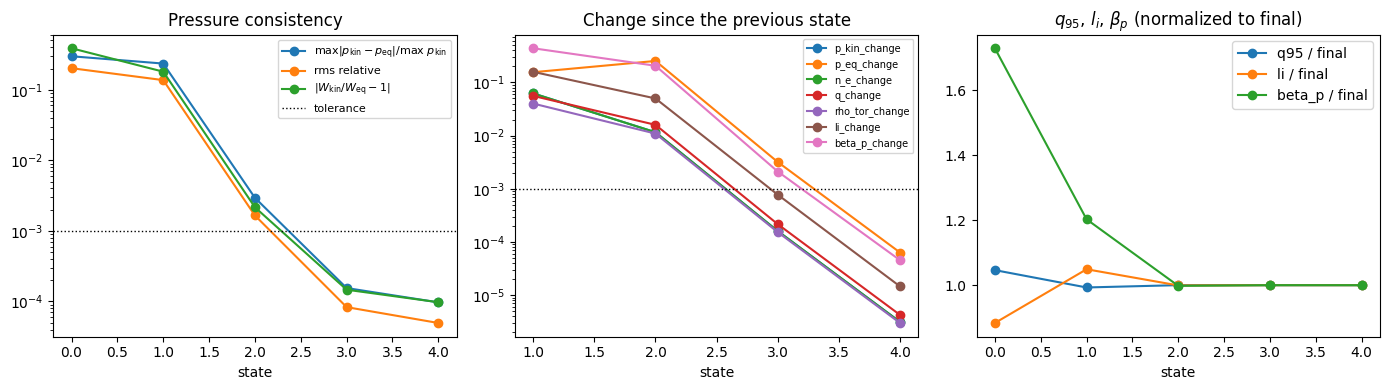

In [18]:
if iteration is not None:
    n = np.arange(len(iteration.states))
    fig, axes = plt.subplots(1, 3, figsize=(14, 4))
    for name, label in (("pressure_max_relative", r"max$|p_\mathrm{kin}-p_\mathrm{eq}|$/max $p_\mathrm{kin}$"),
                        ("pressure_rms_relative", "rms relative"),
                        ("thermal_energy_relative", r"$|W_\mathrm{kin}/W_\mathrm{eq}-1|$")):
        axes[0].semilogy(n, np.abs(iteration.history(name)), "o-", label=label)
    axes[0].axhline(spec.convergence.pressure_rtol, color="k", ls=":", lw=1, label="tolerance")
    axes[0].set(xlabel="state", title="Pressure consistency"); axes[0].legend(fontsize=8)
    for name in ("p_kin_change", "p_eq_change", "n_e_change", "q_change", "rho_tor_change", "li_change",
                 "beta_p_change"):
        axes[1].semilogy(n[1:], np.maximum(iteration.history(name)[1:], 1e-12), "o-", label=name)
    axes[1].axhline(1e-3, color="k", ls=":", lw=1)
    axes[1].set(xlabel="state", title="Change since the previous state"); axes[1].legend(fontsize=7)
    for name, style in (("q95", "C0o-"), ("li", "C1o-"), ("beta_p", "C2o-")):
        values = iteration.history(name)
        axes[2].plot(n, values / values[-1], style, label=f"{name} / final")
    axes[2].set(xlabel="state", title=r"$q_{95}$, $l_i$, $\beta_p$ (normalized to final)"); axes[2].legend()
    fig.tight_layout(); plt.show()

#### Initial against final, and what the solver change contributes

The final pressure is CHEASE's own $p_\mathrm{eq}$, lying on $p_\mathrm{kin}$. Part of the move in
$q_0$, $q_{95}$, $l_i$, $\beta_p$ is the change of solver, not of pressure. The **baseline**
(`baseline=True`) separates them: a CHEASE re-solve of the EFIT equilibrium at its *own* $p'$ and
$FF'$, same normalization and mesh. On this equilibrium the solver change is small
($\Delta q_0\approx-0.02$, $\Delta l_i\approx+0.008$), so almost all of the change comes from the
pressure. The density target is re-applied on each new $V(\psi)$, so $n_e$ is regenerated from the
spec rather than carried over; it ends about 5 % higher than on the EFIT equilibrium because the
traced volume changed. With pure hydrogen $n_i=n_e$.

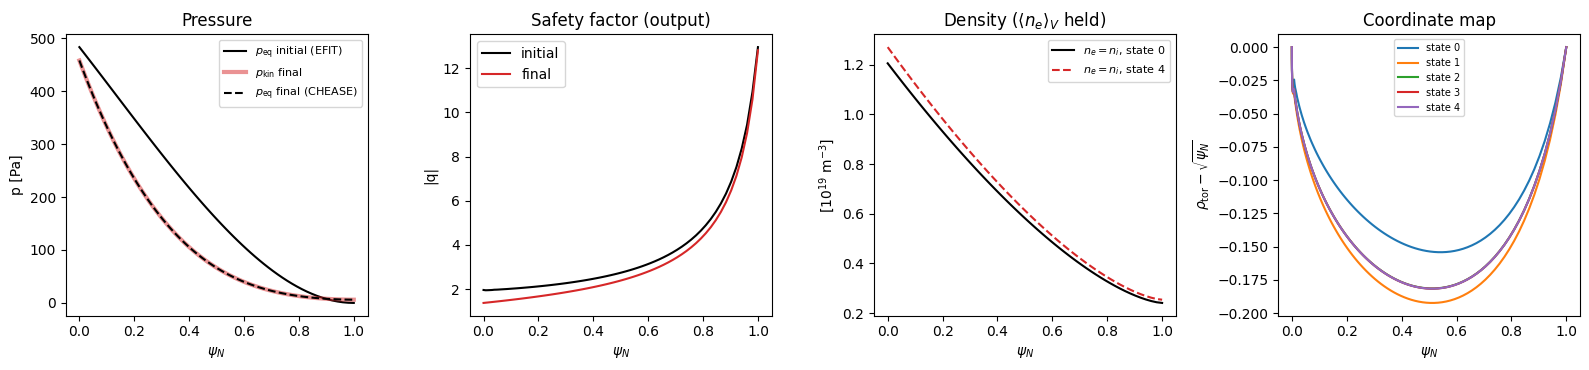

T_e and T_i are declared in psi_N with no normalization, so they are identical in every state: True
rational surfaces, initial: {'q=2': 0.08068616094900097, 'q=3': 0.5697456268540525, 'q=4': 0.7316696365032015}  final: {'q=1.5': 0.09198607863590198, 'q=2': 0.3639153460225809, 'q=3': 0.6388417889277919, 'q=4': 0.76714938193065}
baseline: accepted - CHEASE re-solve of the initial equilibrium at its own p' and FF'


,EFIT (state 0),"CHEASE, EFIT pressure (baseline)","CHEASE, p_kin (final)",solver change,pressure change
q0,1.96,1.935,1.374,-0.02484,-0.5612
q95,8.839,8.854,8.447,0.01561,-0.4073
li,0.6894,0.6969,0.7802,0.007577,0.08327
beta_p,0.2708,0.273,0.1566,0.002159,-0.1164
magnetic_axis_r,0.4813,0.4847,0.4829,0.003469,-0.00181
w_th,280.2,280.2,160.7,-0.0002655,-119.5


In [19]:
if iteration is not None:
    first, last = iteration.initial, iteration.final
    fig, axes = plt.subplots(1, 4, figsize=(16, 3.8))
    axes[0].plot(first.psi_norm, first.p_eq, "k-", label=r"$p_\mathrm{eq}$ initial (EFIT)")
    axes[0].plot(last.psi_norm, last.p_kin, "C3-", lw=3, alpha=0.5, label=r"$p_\mathrm{kin}$ final")
    axes[0].plot(last.psi_norm, last.p_eq, "k--", label=r"$p_\mathrm{eq}$ final (CHEASE)")
    axes[0].set(xlabel=r"$\psi_N$", ylabel="p [Pa]", title="Pressure"); axes[0].legend(fontsize=8)
    axes[1].plot(first.psi_norm, first.q, "k-", label="initial"); axes[1].plot(last.psi_norm, last.q, "C3-", label="final")
    axes[1].set(xlabel=r"$\psi_N$", ylabel="|q|", title="Safety factor (output)"); axes[1].legend()
    for s, style in ((first, "k-"), (last, "C3--")):
        axes[2].plot(s.psi_norm, s.kinetic.n_e / 1e19, style, label=rf"$n_e = n_i$, state {s.index}")
    axes[2].set(xlabel=r"$\psi_N$", ylabel=r"[$10^{19}$ m$^{-3}$]", title=r"Density ($\langle n_e\rangle_V$ held)")
    axes[2].legend(fontsize=8)
    for s in iteration.states:
        axes[3].plot(s.psi_norm, s.rho_tor_norm - np.sqrt(s.psi_norm), label=f"state {s.index}")
    axes[3].set(xlabel=r"$\psi_N$", ylabel=r"$\rho_\mathrm{tor} - \sqrt{\psi_N}$", title="Coordinate map")
    axes[3].legend(fontsize=7)
    fig.tight_layout(); plt.show()
    print("T_e and T_i are declared in psi_N with no normalization, so they are identical in every state:",
          np.array_equal(first.kinetic.T_e, last.kinetic.T_e))
    print("rational surfaces, initial:", dict(first.rational_surfaces), " final:", dict(last.rational_surfaces))
    base = iteration.baseline
    print("baseline:", base.status, "-", base.message)
    names = ("q0", "q95", "li", "beta_p", "magnetic_axis_r", "w_th")
    attribution = pd.DataFrame({
        "EFIT (state 0)": {k: first.scalars[k] for k in names},
        "CHEASE, EFIT pressure (baseline)": {k: base.scalars[k] for k in names},
        "CHEASE, p_kin (final)": {k: last.scalars[k] for k in names},
    })
    attribution["solver change"] = attribution.iloc[:, 1] - attribution.iloc[:, 0]
    attribution["pressure change"] = attribution.iloc[:, 2] - attribution.iloc[:, 1]
    display(attribution)

#### What was held, what was recomputed

The table comes from the result: what the iteration held, what it recomputed from the kinetic
state, what CHEASE recomputed, what is a numerical control and what is a convergence metric. The
CHEASE settings the workflow fixes regardless of the caller's config are in the provenance. The
final accepted pair is one ODS with the CHEASE `equilibrium` and the synthetic `core_profiles`
slice, both labelled assumption-driven.

In [20]:
if iteration is not None:
    display(pd.DataFrame(iteration.assumption_table(), columns=["quantity", "role"]))
    print(pd.Series(dict(iteration.policy)).to_string())
    print()
    for key, why in iteration.provenance["chease_fixed_settings"].items():
        print(f"{key:28s} {why}")
    print("\npressure source:", iteration.iterations[0].pressure_source.method)
    print("round trip p -> p' -> p (max relative):",
          max(s.chease_inputs["pressure_roundtrip_max_relative"] for s in iteration.iterations),
          "(the written PPRIME integrated with the written span)")
    ods = iteration.ods
    print()
    print("equilibrium.code.name       :", ods["equilibrium.code.name"])
    print("core_profiles.code.name     :", ods["core_profiles.code.name"])
    print("time (equilibrium, profiles):", ods["equilibrium.time"], ods["core_profiles.time"])
    print("state basis                 :", iteration.provenance["state_basis"],
          "| transport_predicted =", iteration.provenance["transport_predicted"],
          "| reconstructed =", iteration.provenance["reconstructed"])

,quantity,role
0,"kinetic assumptions (the #122 spec: shapes, targets, T_i route, composition)",held
1,"fixed boundary (the initial equilibrium's RBBBS, target_psin = 1)",held
2,vacuum field F_edge = R0 B0,held
3,normalized FF'(psi_N) shape of the initial equilibrium,held
4,plasma current I_p of the initial equilibrium (CHEASE NCSCAL = 2),held
5,"p_kin, p_e, p_i, n_e, T_e, T_i, n_i, Z_eff",recomputed from the kinetic state
6,PRES and PPRIME handed to CHEASE,recomputed from the kinetic state
7,"psi(R,Z), p_eq, q(psi), FF' amplitude, magnetic axis, l_i, beta",recomputed by CHEASE
8,"rho_tor_norm(psi_N), V(psi), line-average chord",recomputed from the new equilibrium
9,"CHEASE mesh, iteration cap, relaxation",numerical control


kind                                                                                preserve_ffprime_shape
normalization                                                                               plasma_current
ncscal                                                                                                   2
held_target                                                                                      7.704e+04
held_target_unit                                                                                         A
held_target_written_as                                                               input CURRENT (CURRT)
current_profile                                                                                       None
held_shape                                          normalized FF'(psi_N) shape of the initial equilibrium
held_normalization                                           plasma current I_p of the initial equilibrium
chease_ncscal                        

#### The current policy is an assumption too

The same kinetic spec with two other non-pressure policies: $FF'\propto-dg/d\psi_N$ for a declared
$g(\psi_N)$ holding $I_p$, and the initial $FF'$ shape holding $q_{95}$ instead of $I_p$. Each
reaches a consistent state, but not the same one.

,status,updates,max|p_kin-p_eq|/max p_kin,ip,q0,q95,li,beta_p
"initial FF' shape, Ip held",converged,4,9.716e-05,7.704e+04,1.374,8.447,0.7802,0.1566
"analytic g, Ip held",converged,4,8.547e-05,7.704e+04,0.9944,8.012,0.9827,0.1472
"initial FF' shape, q95 held",converged,4,0.0001145,7.339e+04,1.367,8.84,0.7961,0.1715


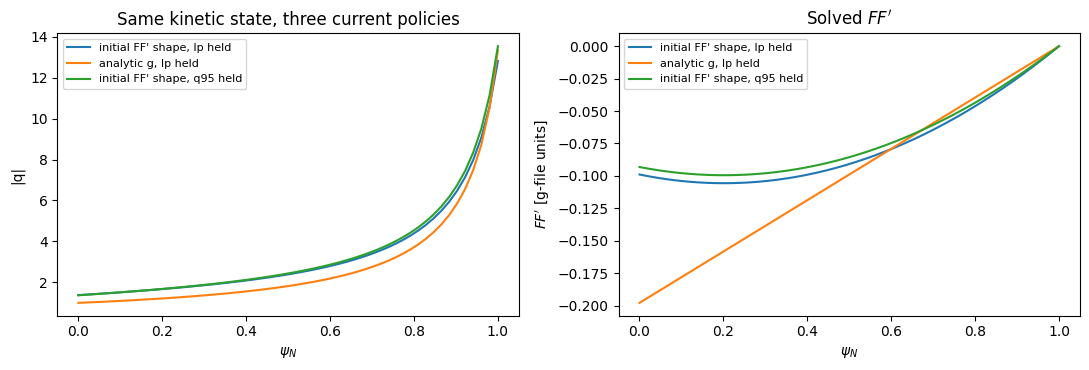

In [21]:
if iteration is not None:
    g_current = compose_analytic_profile("g", unit="", axis_value=1.0, separatrix_value=0.01, core_beta=2.0)
    variants = {
        "initial FF' shape, Ip held": iteration,
        "analytic g, Ip held": build_consistent_state(
            g0, EquilibriumKineticSpec(kinetic, current_policy=CurrentPolicy("analytic_ffprime_shape",
                                                                             current_profile=g_current)),
            config=DEMO_MESH, workdir=WORK / "analytic_current", time=TIME),
        "initial FF' shape, q95 held": build_consistent_state(
            g0, EquilibriumKineticSpec(kinetic, current_policy=CurrentPolicy(normalization="q95")),
            config=DEMO_MESH, workdir=WORK / "q95", time=TIME),
    }
    display(pd.DataFrame({label: {"status": v.status, "updates": len(v.iterations),
                                  "max|p_kin-p_eq|/max p_kin": v.final.metrics["pressure_max_relative"],
                                  **{k: v.final.scalars[k] for k in ("ip", "q0", "q95", "li", "beta_p")}}
                          for label, v in variants.items()}).T)
    fig, (ax, bx) = plt.subplots(1, 2, figsize=(11, 3.8))
    for label, v in variants.items():
        ax.plot(v.final.psi_norm, v.final.q, label=label)
        g = v.final.equilibrium
        bx.plot(np.linspace(0, 1, int(g["NW"])), np.asarray(g["FFPRIM"]), label=label)
    ax.set(xlabel=r"$\psi_N$", ylabel="|q|", title="Same kinetic state, three current policies"); ax.legend(fontsize=8)
    bx.set(xlabel=r"$\psi_N$", ylabel=r"$FF'$ [g-file units]", title=r"Solved $FF'$"); bx.legend(fontsize=8)
    fig.tight_layout(); plt.show()
else:
    print("Skipping the current-policy variants (CHEASE solves).")

#### Refusal and non-convergence are results, not exceptions

- A **hollow** kinetic pressure has a $p'$ that changes sign. The adapter's `EXPEQ` carries $-|p'|$,
  so such a pressure cannot be handed to CHEASE faithfully; it is refused before any solve with
  `invalid_pressure_source`. This needs no solver and always runs.
- A **cap too small** for the tolerances ends as `max_iterations`; the last accepted pair is still
  written and the unmet criteria are named.

The other end states (`chease_failed`, `validation_failed`, `kinetic_generation_failed`, `diverged`,
`oscillating`, `stagnated`) are exercised offline in `test/test_equilibrium_kinetic_iteration.py`;
every state keeps its diagnostics.

In [22]:
hollow_T_e = TabulatedProfile(np.array([0.0, 0.5, 1.0]), np.array([60.0, 200.0, 20.0]),
                              coordinate="psi_norm", unit="eV")
hollow = EquilibriumKineticSpec(SyntheticKineticSpec(n_e=kinetic.n_e, T_e=ProfileSpec(hollow_T_e),
                                                     temperature=kinetic.temperature, pressure_constraint="kinetic"))
refused = build_consistent_state(g0, hollow, config=DEMO_MESH, workdir=WORK / "hollow", time=TIME)
assert refused.status == "invalid_pressure_source"
print(refused.status, "-", refused.message)
print("CHEASE work directories created:", sorted(p.name for p in (WORK / "hollow").glob("iteration_*")))

if EXECUTE_CHEASE:
    capped = build_consistent_state(g0, EquilibriumKineticSpec(kinetic, convergence=ConvergenceCriteria(max_iterations=2)),
                                    config=DEMO_MESH, workdir=WORK / "capped", time=TIME)
    print(capped.status, "-", capped.message)
    print("final state:", capped.final.index, "| ODS written:", capped.ods is not None)
else:
    print("Skipping the capped (max_iterations) run (CHEASE solves).")

invalid_pressure_source - the kinetic pressure rises outward near psi_N = 0.000; CHEASE's EXPEQ carries p' of one sign (the adapter writes -|p'|), so a hollow pressure cannot be handed to it faithfully
CHEASE work directories created: []


max_iterations - 2 updates without meeting every criterion; unmet: pressure_rtol, profile_rtol, q_rtol, coordinate_atol, scalar_rtol, axis_atol
final state: 2 | ODS written: True


## 6. Comparative interpretation and limitations

| | §3 Inference on magnetic EFIT | §4 Kinetic-constrained EFIT | §5 Synthetic iteration |
|---|---|---|---|
| **Measured** | Thomson $n_e$, $T_e$ (5 channels, 1σ); magnetic signals behind EFIT | the same Thomson channels; magnetic signals | nothing |
| **Assumed** | $n_C=n_O$, $\langle Z_\mathrm{eff}\rangle_{n_e dV}=2$, common $T_i$, transient charge-state model | $T_i/T_e=1\pm0.5$, $n_i=n_e$, edge anchor | kinetic profile shapes and targets, $T_i/T_e$, current policy and normalization, fixed boundary |
| **Inferred** | $T_i$, $p_i$; ion densities and $Z_\mathrm{eff}(\rho)$ (model-derived) | nothing — the partition is refused as circular | nothing |
| **Reconstructed / recomputed** | — (the equilibrium is not touched) | $p_\mathrm{eq}^\mathrm{kin}$, $\psi$, the Thomson mapping | $\psi(R,Z)$, $p_\mathrm{eq}$, $q$, $FF'$ amplitude, $l_i$, $\beta_p$, coordinate maps, regenerated profiles |
| **Independent evidence** | Thomson pressure against the magnetics-only $p_\mathrm{eq}$ (5 points, positive residuals for 40326) | — (Thomson entered the fit) | — (nothing measured) |
| **Gates and acceptance checks** (not evidence) | charge-state and $T_i$ validity masks | archived admissibility gate (39915 fail, 40326 pass) | acceptance checks of each solve; the EFIT→CHEASE baseline attribution |
| **Imposed by closure** | $p_e+p_i=p_\mathrm{eq}$ at every valid point | — | $p_\mathrm{kin}=p_\mathrm{eq}$ in `equilibrium_pressure` mode |
| **Numerically converged** | — | the EFIT solve (both shots) | the `kinetic_pressure` loop to $\sim10^{-4}$, under stated tolerances |

**What each does not establish.**

- §3 does not test the equilibrium: the pressure overlay is an identity after $T_i$ inference. The
  composition is a premise; no spectroscopic or resistive result identifies it (a resistive
  $Z_\mathrm{eff}$ estimate for 39915 hit its lower bound). Profiles and $T_i$ beyond the last
  Thomson channel ($\rho\approx0.53$ for 39915, $0.48$ for 40326) depend on the fit and composition,
  and no uncertainty is propagated to $T_i$, $n_\mathrm{imp}$ or $Z_\mathrm{eff}$. The derived state
  has not been written back to the source products.
- §4: a converged, valid reconstruction can still fail admissibility (39915), and an admissible one
  (40326) still used $n_i=n_e$. Neither is an impurity-consistent joint reconstruction; that needs a
  new fit with an impurity-diluted constraint and a fresh admissibility assessment.
- §5 converges for its assumptions only. Each current policy reaches a different consistent state;
  none predicts the current profile. Mixed or partial closures are not implemented, restart works
  only from an in-memory result (`resume=`), and the resolution sensitivity of the converged state
  is not studied on this demo mesh.